In [6]:
import pandas as pd
import numpy as np
import re

In [7]:
belief_col = ['Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol','Belief_opinion_on_the_number_of_immigrants_in_america_Symbol']

In [8]:
anes2024 = pd.read_csv('../../original_data/anes_timeseries_2024_csv_20250808/anes_timeseries_2024_csv_20250808.csv')
anes2024

C:\Users\yuyue\AppData\Local\Temp\ipykernel_15896\3777620387.py:1: DtypeWarning: Columns (8,10,11,16,18,19,20,22,23,24,26,27,28,30,31,36,38,39,1448,1449,1450,1451,1452,1455,1456,1457,1458,1459,1463,1464,1465) have mixed types. Specify dtype option on import or set low_memory=False.
  anes2024 = pd.read_csv('../../original_data/anes_timeseries_2024_csv_20250808/anes_timeseries_2024_csv_20250808.csv')


,version,V240001,V200001,V160001_orig,V240002a,V240002b,V240002c,V240003,V240101a,V240101b,...,V245009,V245010,V245011,V245012,V245013,V245014,V245015,V245016,V245017,V245018
0,ANES2024TimeSeries_20250808,140001,200015,401318,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
1,ANES2024TimeSeries_20250808,140002,200022,300261,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
2,ANES2024TimeSeries_20250808,140003,200039,400181,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
3,ANES2024TimeSeries_20250808,140004,200046,300171,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
4,ANES2024TimeSeries_20250808,140005,200053,405145,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5516,ANES2024TimeSeries_20250808,399764,-1,-1,1,-6,1,3,0.117236,,...,0,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
5517,ANES2024TimeSeries_20250808,399815,-1,-1,1,5,2,3,1.501748,1.15260127111406,...,1,IWER76,1960,3,0,1,5,0,1,0
5518,ANES2024TimeSeries_20250808,399830,-1,-1,1,-6,1,3,1.114477,,...,2,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
5519,ANES2024TimeSeries_20250808,399841,-1,-1,4,4,2,3,1.179447,1.1924221171493,...,2,IWER75,1950,3,0,1,5,0,1,2


In [9]:
cces2024 = pd.read_csv('../../original_data/CCES_2024/CCES24_Common_OUTPUT_vv_topost_final.csv')
cces2024

,caseid,tookpost,commonweight,commonpostweight,vvweight,vvweight_post,CCEStake,add_confirm,inputzip,birthyr,...,starttime_post,endtime_post,TS_g2024,TS_voterstatus,TS_p2024,TS_p2024_party,TS_pp2024,TS_pp2024_party,TS_state,TS_partyreg
0,1853651564,2,0.418897,0.180057,1.407497,0.822485,1,1.0,NaN,1978,...,2024-11-09 03:00:05,2024-11-09 03:09:39,3.0,1.0,7.0,NaN,7.0,NaN,PA,2.0
1,1853655732,2,0.946650,0.700897,0.470183,0.435126,1,NaN,11236.0,1968,...,2024-11-10 22:46:35,2024-11-10 22:56:59,2.0,1.0,7.0,NaN,7.0,NaN,NY,8.0
2,1852716424,2,0.194303,0.046275,0.245400,0.172787,1,1.0,NaN,1946,...,2024-11-11 03:52:52,2024-11-11 04:11:38,3.0,1.0,7.0,NaN,7.0,NaN,PA,NaN
3,1853644254,2,0.083223,0.008897,0.465415,0.636743,1,NaN,90039.0,2001,...,2024-12-08 03:31:26,2024-12-08 04:30:16,1.0,1.0,7.0,NaN,7.0,NaN,CA,NaN
4,1853644132,2,0.596598,0.555395,1.676258,1.609462,1,1.0,NaN,1955,...,2024-11-06 23:47:48,2024-11-07 00:27:52,1.0,1.0,1.0,NaN,7.0,NaN,MT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,1906098636,2,0.255305,2.469711,2.747473,2.730659,1,1.0,NaN,1950,...,2024-11-11 03:23:14,2024-11-11 03:42:51,4.0,1.0,4.0,6.0,7.0,NaN,ID,8.0
59996,1904587154,2,0.964466,0.931537,0.752686,0.654171,1,1.0,NaN,1981,...,2024-12-06 01:06:11,2024-12-06 01:20:46,6.0,1.0,6.0,1.0,7.0,NaN,IL,NaN
59997,1906111230,2,0.246773,0.195502,0.261751,0.619091,1,NaN,89118.0,1955,...,2024-12-02 00:08:50,2024-12-02 00:31:20,3.0,1.0,3.0,NaN,7.0,NaN,NV,2.0
59998,1906096834,2,3.177289,8.421328,6.707039,8.972966,1,1.0,NaN,2000,...,2024-11-09 14:06:22,2024-11-09 14:19:11,4.0,1.0,7.0,NaN,7.0,NaN,NJ,2.0


In [10]:
cces2024['gender4'].value_counts()

gender4
2    31992
1    27454
3      448
4      106
Name: count, dtype: int64

In [11]:
cces2024.columns.to_list()

['caseid',
 'tookpost',
 'commonweight',
 'commonpostweight',
 'vvweight',
 'vvweight_post',
 'CCEStake',
 'add_confirm',
 'inputzip',
 'birthyr',
 'gender4',
 'gender4_t',
 'educ',
 'race',
 'race_other',
 'hispanic',
 'multrace_1',
 'multrace_2',
 'multrace_3',
 'multrace_4',
 'multrace_5',
 'multrace_8',
 'multrace_97',
 'multrace_98',
 'comptype',
 'votereg',
 'votereg_f',
 'regzip',
 'pid3',
 'pid3_t',
 'pid7',
 'inputstate',
 'region',
 'ccesmodule',
 'CC24_300_1',
 'CC24_300_2',
 'CC24_300_3',
 'CC24_300_4',
 'CC24_300_5',
 'CC24_300a',
 'CC24_300c',
 'CC24_300b_1',
 'CC24_300b_2',
 'CC24_300b_3',
 'CC24_300b_4',
 'CC24_300b_5',
 'CC24_300b_6',
 'CC24_300b_7',
 'CC24_300b_8',
 'CC24_300d_1',
 'CC24_300d_2',
 'CC24_300d_3',
 'CC24_300d_4',
 'CC24_300d_5',
 'CC24_300d_6',
 'CC24_301',
 'CC24_302',
 'CC24_303',
 'CC24_305_1',
 'CC24_305_2',
 'CC24_305_3',
 'CC24_305_4',
 'CC24_305_5',
 'CC24_305_6',
 'CC24_305_7',
 'CC24_305_9',
 'CC24_305_10',
 'CC24_305_11',
 'CC24_305_12',
 'CC2

In [12]:
gss = pd.read_excel("../../generated_data/GSS_Immigrant_with_multirace/batch_0/result/GSS.xlsx", sheet_name="Data")
gss

,year,id_,age,degree,sex,partyid,letin1a,racecen1,racecen2,dateintv,ballot,income16,pres20
0,2024,1,33,Bachelor's,MALE,Not very strong democrat,Reduced a little,Black or African American,.i: Inapplicable,927,Ballot b,"$110,000 to $129,999",Biden
1,2024,2,64,Graduate,MALE,Strong democrat,Reduced a little,White,.i: Inapplicable,619,Ballot b,"$60,000 to $74,999",Biden
2,2024,3,69,Associate/junior college,FEMALE,Strong democrat,Remain the same as it is,White,.i: Inapplicable,621,Ballot c,"$110,000 to $129,999",Biden
3,2024,4,19,High school,MALE,"Independent (neither, no response)",.d: Do not Know/Cannot Choose,Some other race,.i: Inapplicable,814,Ballot a,"$150,000 to $169,999",.i: Inapplicable
4,2024,5,70,High school,FEMALE,"Independent (neither, no response)",Reduced a lot,White,.i: Inapplicable,921,Ballot c,"$60,000 to $74,999",Trump
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3304,2024,3305,84,Graduate,MALE,Not very strong democrat,Increased a little,White,.i: Inapplicable,428,Ballot c,"$4,000 to $4,999",Biden
3305,2024,3306,68,High school,MALE,"Independent, close to democrat",Remain the same as it is,White,.i: Inapplicable,423,Ballot a,"$75,000 to $89,999",Biden
3306,2024,3307,74,High school,FEMALE,"Independent (neither, no response)",Reduced a lot,White,.i: Inapplicable,730,Ballot a,"$50,000 to $59,999",.i: Inapplicable
3307,2024,3308,51,Graduate,FEMALE,"Independent, close to democrat",Remain the same as it is,White,.i: Inapplicable,1020,Ballot b,"$75,000 to $89,999",Biden


In [13]:
anes2024['V241550'].value_counts()

V241550
 2    2931
 1    2544
-9      46
Name: count, dtype: int64

Text(0, 0.5, 'Count')

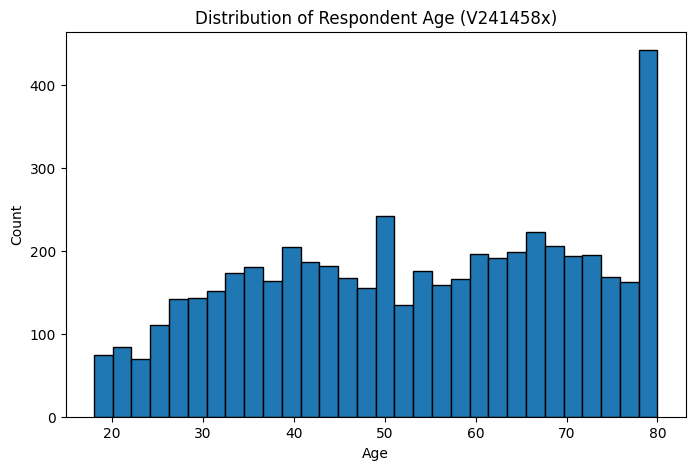

In [14]:
age = pd.to_numeric(anes2024["V241458x"])
age = age[(age >= 18) & (age <= 100)]

ax = age.plot(kind="hist", bins=30, edgecolor="black", figsize=(8, 5), title="Distribution of Respondent Age (V241458x)")
ax.set_xlabel("Age")
ax.set_ylabel("Count")

In [15]:
anes2024['V241458x'].value_counts()

V241458x
 80    333
-2     279
 66    118
 61    111
 40    108
      ... 
 24     38
 23     32
 18     28
 20     26
 19     21
Name: count, Length: 64, dtype: int64

In [16]:
anes2024['sex'] = anes2024['V241550'].map({1: 'Male', 2: 'Female'})
anes2024["sex"].value_counts()

sex
Female    2931
Male      2544
Name: count, dtype: int64

In [17]:
cces2024['gender4'].value_counts()

gender4
2    31992
1    27454
3      448
4      106
Name: count, dtype: int64

In [18]:
cces2024['sex'] = cces2024['gender4'].map({1: 'Male', 2: 'Female'})
cces2024["sex"].value_counts()

sex
Female    31992
Male      27454
Name: count, dtype: int64

In [19]:
gss["sex"] = gss["sex"].str.capitalize()
gss = gss[gss["sex"].isin(["Female", "Male"])].copy()
gss["sex"].value_counts()

sex
Female    1823
Male      1467
Name: count, dtype: int64

In [20]:
cces2024['birthyr'].value_counts()

birthyr
1960    1618
1961    1589
1962    1556
1963    1485
1957    1429
        ... 
1929      12
1931      11
1932      11
1930       9
1928       3
Name: count, Length: 79, dtype: int64

In [21]:
cces2024['age_num'] = 2024 - cces2024['birthyr']
cces2024['age_num']

0        46
1        56
2        78
3        23
4        69
         ..
59995    74
59996    43
59997    69
59998    24
59999    73
Name: age_num, Length: 60000, dtype: int64

In [22]:
# Age group
cces2024['age'] = pd.cut(
    cces2024['age_num'],
    bins=[18, 35, 55, np.inf],
    labels=['18-34', '35-54', '55+']
)
cces2024['age'].value_counts()

age
55+      30013
35-54    17387
18-34    12132
Name: count, dtype: int64

In [23]:
# Age group: ANES V241458x is continuous age
anes2024['age'] = pd.cut(
    anes2024['V241458x'],
    bins=[18, 35, 55, np.inf],
    labels=['18-34', '35-54', '55+']
)

In [24]:
anes2024['age'].value_counts()

age
55+      2501
35-54    1699
18-34    1014
Name: count, dtype: int64

In [25]:
gss = gss[~gss["age"].astype(str).str.contains(r"No answer", na=False)].copy()
gss["age"] = gss["age"].replace("89 or older", 89)
gss["age_num"] = pd.to_numeric(gss["age"])
age_bins = [18, 35, 55, np.inf]
age_labels = ['18-34', '35-54', '55+']

# Create age group variable
gss["age"] = pd.cut(
    gss["age_num"],
    bins=age_bins,
    labels=age_labels
)
gss["age"].value_counts()

age
55+      1326
35-54    1083
18-34     758
Name: count, dtype: int64

In [26]:
# Income group: 1-14 -> <50k, 15-22 -> 50-100k, 23+ -> >100k
income_code = pd.to_numeric(anes2024['V241566x'])

anes2024['income'] = np.select(
    [
        income_code.between(1, 14),
        income_code.between(15, 22),
        income_code >= 23
    ],
    ['<50k', '50-100k', '100k+'],
    default=None
)
anes2024['income'].value_counts()

income
100k+      1954
<50k       1620
50-100k    1391
Name: count, dtype: int64

In [27]:
cces2024['faminc_new'].value_counts()

faminc_new
3.0     5849
4.0     5236
97.0    5119
9.0     4853
6.0     4817
5.0     4764
2.0     4373
11.0    4083
8.0     4058
10.0    3929
7.0     3679
1.0     3259
12.0    3037
13.0    1366
14.0     912
15.0     375
16.0     268
Name: count, dtype: int64

In [28]:
income_code = pd.to_numeric(cces2024['faminc_new'])

cces2024['income'] = np.select(
    [
        income_code.between(1, 5),
        income_code.between(6, 9),
        income_code.between(9, 16)
    ],
    ['<50k', '50-100k', '100k+'],
    default=None
)
cces2024['income'].value_counts()

income
<50k       23481
50-100k    17407
100k+      13970
Name: count, dtype: int64

In [29]:
# Normalize income to bins
def extract_income_lower(income_str):
    if pd.isna(income_str):
        return np.nan
    # Remove $ and commas
    income_str = income_str.replace("$", "").replace(",", "")
    # Match first number
    match = re.match(r"(\d+)", income_str)
    if match:
        return float(match.group(1))
    return np.nan

gss = gss.copy()
gss["income_num"] = gss["income16"].apply(extract_income_lower)
income_bins = [0, 50000, 100000, np.inf]
income_labels = ['<50k', '50-100k', '100k+']
gss.loc[:, "income"] = pd.cut(
    gss["income_num"],
    bins=income_bins,
    labels=income_labels,
    right=False,
    include_lowest=True
)
gss["income"].value_counts()

income
<50k       1102
50-100k     962
100k+       748
Name: count, dtype: int64

In [30]:
# Ethnicity: ANES V241501x → 1=White, Other = Non-White
anes2024['eth'] = anes2024['V241501x'].map({
    1: 'White', 2: 'Non-white', 3: 'Non-white', 4: 'Non-white', 5: 'Non-white', 6: 'Non-white'
})
anes2024['eth'].value_counts()

eth
White        3946
Non-white    1508
Name: count, dtype: int64

In [31]:
cces2024['race'].value_counts()

race
1    41443
2     7728
3     5150
4     1949
6     1947
7     1035
5      582
8      166
Name: count, dtype: int64

In [32]:
cces2024['eth'] = cces2024['race'].map({
    1: 'White', 2: 'Non-white', 3: 'Non-white', 4: 'Non-white', 5: 'Non-white', 6: 'Non-white',7: 'Non-white',8: 'Non-white'
})
cces2024['eth'].value_counts()

eth
White        41443
Non-white    18557
Name: count, dtype: int64

In [33]:
# Update ethnicity mapping: use racecen2 to identify multiracial respondents
eth_align_map = {
    "White": "White",
    "Black or African American": "Non-white",
    "American Indian or Alaska Native": "Non-white",
    "Asian Indian": "Non-white",
    "Chinese": "Non-white",
    "Filipino": "Non-white",
    "Japanese": "Non-white",
    "Korean": "Non-white",
    "Vietnamese": "Non-white",
    "Other Asian": "Non-white",
    "Other Pacific Islander": "Non-white",
    "Some other race": "Non-white",
    "Hispanic": "Non-white"
}

# Base ethnicity from racecen1
gss.loc[:, "eth"] = gss["racecen1"].map(eth_align_map)

# If racecen2 has a valid second-race answer, force Multiracial
invalid_racecen2 = {
    ".i:  Inapplicable",
    ".n:  No answer",
    ".d:  Do not Know/Cannot Choose",
    ".s:  Skipped on Web"
}

racecen2_clean = gss["racecen2"].astype(str).str.strip()
valid_second_race_mask = gss["racecen2"].notna() & (~racecen2_clean.isin(invalid_racecen2))
gss.loc[valid_second_race_mask, "eth"] = "Non-white"

gss["eth"].value_counts()

eth
White        2164
Non-white     977
Name: count, dtype: int64

In [34]:
# Education: ANES V241465x → Non-Colledge,Colledge
anes2024['education'] = anes2024['V241465x'].map({
    1: 'Non-college', 2: 'Non-college', 3: 'Non-college', 4: 'College', 5: 'College'
})
anes2024['education'].value_counts()

education
Non-college    2994
College        2471
Name: count, dtype: int64

In [35]:
cces2024['educ'].value_counts()

educ
2    15983
3    13961
5    13297
6     7960
4     6666
1     2133
Name: count, dtype: int64

In [36]:
cces2024['education'] = cces2024['educ'].map({
    1: 'Non-college', 2: 'Non-college', 3: 'Non-college', 4: 'College', 5: 'College', 6: 'College'
})
cces2024['education'].value_counts()

education
Non-college    32077
College        27923
Name: count, dtype: int64

In [37]:
# Map education categories
edu_align_map = {
    "High school": 'Non-college',
    "Less than high school": 'Non-college',
    "Bachelor's": 'College',
    "Graduate": 'College',
    "Associate/junior college": 'College',
    ".d:  Do not Know/Cannot Choose": np.nan
}
gss.loc[:, "education"] = gss["degree"].map(edu_align_map)

gss['education'].value_counts()

education
Non-college    1751
College        1444
Name: count, dtype: int64

In [38]:
# Vote: ANES V241106x
anes2024['vote'] = anes2024['V241106x'].map({
    1: 'StayHome', 2: 'Democratic', 3: 'Republican', 4: 'Other'
})
anes2024['vote'].value_counts()

vote
Democratic    2433
Republican    1821
StayHome      1155
Other           65
Name: count, dtype: int64

In [39]:
cces2024['vote'] = cces2024['presvote20post'].map({
    1: 'Democratic', 2: 'Republican', 3: 'Other', 4: 'Other', 5: 'Other', 6: 'StayHome'
})
cces2024['vote'].value_counts()

vote
Democratic    26942
Republican    19433
StayHome      11921
Other          1660
Name: count, dtype: int64

In [40]:
cces2024['presvote20post'].value_counts()

presvote20post
1.0    26942
2.0    19433
6.0    11921
3.0      784
5.0      610
4.0      266
Name: count, dtype: int64

In [41]:
# Normalize past vote to simplified categories
vote_align_map = {
    "Biden": "Democratic",      
    "Trump": "Republican",     
    "Other candidate": "Other",
    "Didn't vote for president": "StayHome",
}
gss.loc[:, "vote"] = gss["pres20"].map(vote_align_map)
gss["vote"].value_counts()

vote
Democratic    1164
Republican     859
Other           51
StayHome        13
Name: count, dtype: int64

In [42]:
# State: ANES V242058x
# state mapping data for anes
codes = [-1] + list(range(1, 3)) + list(range(4, 7)) + list(range(8, 14)) + \
        list(range(15, 43)) + list(range(44, 52)) + list(range(53, 57))

levels = [
    np.nan, 'Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 
    'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 
    'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 
    'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 
    'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 
    'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 
    'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 
    'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 
    'Washington', 'West Virginia', 'Wisconsin', 'Wyoming'
]

# Create a dictionary for the mapping
state_map = dict(zip(codes, levels))

# Apply the mapping to anes
anes2024['state_simple'] = anes2024['V242058x'].map(state_map).astype('category')

In [43]:
anes2024['V240108b'].value_counts()

V240108b
                     757
5.00000000498223     105
.238504135225957       2
.683671970390806       2
.859994166460876       2
                    ... 
.596674076518462       1
.0948685952731166      1
1.90730910362323       1
2.56436072555069       1
1.34915930327876       1
Name: count, Length: 4658, dtype: int64

In [44]:
codes = [-1] + list(range(1, 3)) + list(range(4, 7)) + list(range(8, 14)) + \
        list(range(15, 43)) + list(range(44, 52)) + list(range(53, 57))

levels = [
    np.nan, 'Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 
    'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 
    'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 
    'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 
    'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 
    'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 
    'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 
    'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 
    'Washington', 'West Virginia', 'Wisconsin', 'Wyoming'
]

# Create a dictionary for the mapping
state_map = dict(zip(codes, levels))

# Apply the mapping to cces2024
cces2024['state_simple'] = cces2024['inputstate'].map(state_map).astype('category')

In [45]:
states = cces2024['inputstate'].dropna().sort_values().unique()
print(states)

[ 1  2  4  5  6  8  9 10 11 12 13 15 16 17 18 19 20 21 22 23 24 25 26 27
 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 44 45 46 47 48 49 50 51 53
 54 55 56]


In [46]:
cces2024['state_simple'].value_counts() 

state_simple
California              4900
Texas                   4816
Florida                 4402
New York                3453
Pennsylvania            3040
Ohio                    2564
Illinois                2320
Georgia                 2055
Michigan                1951
North Carolina          1913
Virginia                1611
New Jersey              1604
Arizona                 1495
Washington              1382
Tennessee               1371
Wisconsin               1334
Missouri                1323
Indiana                 1267
Massachusetts           1119
Maryland                1068
Colorado                1055
Minnesota               1016
Oregon                  1009
South Carolina           992
Alabama                  901
Kentucky                 887
Nevada                   739
Louisiana                709
Oklahoma                 701
Iowa                     615
Connecticut              594
Arkansas                 532
Utah                     507
Mississippi              503
K

# find the time window where most observation are collected

In [47]:
df = pd.read_pickle('../../generated_data/feature_extraction/preprocessed_cleaned_all_result.pkl')

In [48]:
df['time_window_start'] = pd.to_datetime(df['time_window_start']).dt.tz_localize(None)
time_window = df['time_window_start'].unique()
time_window

<DatetimeArray>
['2023-11-05 00:00:00', '2023-11-19 00:00:00', '2023-12-03 00:00:00',
 '2023-12-17 00:00:00', '2023-12-31 00:00:00', '2024-01-14 00:00:00',
 '2024-01-28 00:00:00', '2024-02-11 00:00:00', '2024-02-25 00:00:00',
 '2024-03-10 00:00:00', '2024-04-07 00:00:00', '2024-10-06 00:00:00',
 '2024-10-20 00:00:00', '2024-03-24 00:00:00', '2024-04-21 00:00:00',
 '2024-05-05 00:00:00', '2024-05-19 00:00:00', '2024-06-16 00:00:00',
 '2024-06-30 00:00:00', '2024-07-14 00:00:00', '2024-07-28 00:00:00',
 '2024-08-11 00:00:00', '2024-08-25 00:00:00', '2024-09-08 00:00:00',
 '2024-09-22 00:00:00', '2024-06-02 00:00:00']
Length: 26, dtype: datetime64[ns]

for time stamps in the list time_window, use them as cut points and form bins of time windows, then check the time stamp in anes2024['V243050'], which bin of time window it falls into, in the end print a table that counts the number of rows where anes2024['V243050'] fall into the bin in each bin in time_window

In [49]:
cut_points = pd.DatetimeIndex(time_window).sort_values().unique()

obs_time = pd.to_datetime(anes2024["V243050"].astype(str), format="%Y%m%d", errors="coerce")
last_cut = cut_points.max()
upper_bound = last_cut + pd.Timedelta(days=14)

bins = cut_points.append(pd.DatetimeIndex([upper_bound]))

bin_labels = [
    f"[{bins[i].date()} , {bins[i+1].date()})"
    for i in range(len(bins) - 1)
]

bin_assignments = pd.cut(
    obs_time,
    bins=bins,
    labels=bin_labels,
    right=False,
    include_lowest=True
)

bin_counts = (
    bin_assignments.value_counts(dropna=False)
    .reindex(bin_labels, fill_value=0)
    .reset_index()
)
bin_counts.columns = ["time_window_bin", "row_count"]

bin_counts

,time_window_bin,row_count
0,"[2023-11-05 , 2023-11-19)",0
1,"[2023-11-19 , 2023-12-03)",0
2,"[2023-12-03 , 2023-12-17)",0
3,"[2023-12-17 , 2023-12-31)",0
4,"[2023-12-31 , 2024-01-14)",0
5,"[2024-01-14 , 2024-01-28)",0
6,"[2024-01-28 , 2024-02-11)",0
7,"[2024-02-11 , 2024-02-25)",0
8,"[2024-02-25 , 2024-03-10)",0
9,"[2024-03-10 , 2024-03-24)",0


In [50]:
type(cces2024['starttime'][1])

str

In [51]:
cces2024['starttime'].value_counts()

starttime
2024-10-12 15:19:00    4
2024-10-15 19:29:52    4
2024-10-16 02:59:55    3
2024-10-15 23:21:35    3
2024-10-15 22:00:10    3
                      ..
2024-11-03 19:13:54    1
2024-11-04 00:29:16    1
2024-11-04 00:40:30    1
2024-11-04 03:08:54    1
2024-11-02 01:56:23    1
Name: count, Length: 58417, dtype: int64

In [52]:
obs_time

0      2024-08-12
1      2024-08-18
2      2024-08-09
3      2024-08-15
4      2024-08-14
          ...    
5516   2024-10-24
5517   2024-09-27
5518   2024-10-06
5519   2024-11-01
5520   2024-09-17
Name: V243050, Length: 5521, dtype: datetime64[ns]

In [53]:
cut_points = pd.DatetimeIndex(time_window).sort_values().unique()

obs_time = pd.to_datetime(cces2024["starttime"]).dt.normalize()
last_cut = cut_points.max()
upper_bound = last_cut + pd.Timedelta(days=14)

bins = cut_points.append(pd.DatetimeIndex([upper_bound]))

bin_labels = [
    f"[{bins[i].date()} , {bins[i+1].date()})"
    for i in range(len(bins) - 1)
]

bin_assignments = pd.cut(
    obs_time,
    bins=bins,
    labels=bin_labels,
    right=False,
    include_lowest=True
)

bin_counts = (
    bin_assignments.value_counts(dropna=False)
    .reindex(bin_labels, fill_value=0)
    .reset_index()
)
bin_counts.columns = ["time_window_bin", "row_count"]

bin_counts

,time_window_bin,row_count
0,"[2023-11-05 , 2023-11-19)",0
1,"[2023-11-19 , 2023-12-03)",0
2,"[2023-12-03 , 2023-12-17)",0
3,"[2023-12-17 , 2023-12-31)",0
4,"[2023-12-31 , 2024-01-14)",0
5,"[2024-01-14 , 2024-01-28)",0
6,"[2024-01-28 , 2024-02-11)",0
7,"[2024-02-11 , 2024-02-25)",0
8,"[2024-02-25 , 2024-03-10)",0
9,"[2024-03-10 , 2024-03-24)",0


In [54]:
gss['dateintv'].value_counts()

dateintv
523     85
1017    64
522     61
1018    47
729     45
        ..
818      3
1001     3
1005     2
1003     1
405      1
Name: count, Length: 242, dtype: int64

In [55]:
def convert_dateintv_to_datetime(dateintv):
    """
    Convert GSS dateintv format (MMDD) to datetime.
    """
    
    # label non-numeric entries (e.g., ".n:  No answer") to NaT
    if isinstance(dateintv, str):
        digits = re.sub(r"\D", "", dateintv)
        if digits == "":
            return pd.NaT
        dateintv = digits
    
    dateintv_num = pd.to_numeric(dateintv)
    
    dateintv_str = str(int(dateintv_num)).zfill(4)  
    month = int(dateintv_str[:2])
    day = int(dateintv_str[2:])
    
    # Determine year based on context 
    year = 2024
    
    return pd.to_datetime(f"{year}-{month:02d}-{day:02d}")

In [56]:
def convert_dateintv_to_datetime(dateintv):
    """
    Convert GSS dateintv format (MMDD) to datetime.
    """
    if pd.isna(dateintv):
        return pd.NaT
    
    # Coerce non-numeric entries (e.g., ".n:  No answer") to NaT
    if isinstance(dateintv, str):
        digits = re.sub(r"\D", "", dateintv)
        if digits == "":
            return pd.NaT
        dateintv = digits
    
    dateintv_num = pd.to_numeric(dateintv, errors="coerce")
    if pd.isna(dateintv_num):
        return pd.NaT
    
    dateintv_str = str(int(dateintv_num)).zfill(4)  # Ensure 4 digits (e.g., '0427' for April 27)
    month = int(dateintv_str[:2])
    day = int(dateintv_str[2:])
    
    # Determine year based on context 
    year = 2024
    
    try:
        return pd.to_datetime(f"{year}-{month:02d}-{day:02d}")
    except:
        return pd.NaT

In [57]:
gss['interview_date'] = gss['dateintv'].apply(convert_dateintv_to_datetime)
gss['interview_date'].value_counts()

interview_date
2024-05-23    85
2024-10-17    64
2024-05-22    61
2024-10-18    47
2024-07-29    45
              ..
2024-08-18     3
2024-10-01     3
2024-10-05     2
2024-10-03     1
2024-04-05     1
Name: count, Length: 242, dtype: int64

In [58]:
cut_points

DatetimeIndex(['2023-11-05', '2023-11-19', '2023-12-03', '2023-12-17',
               '2023-12-31', '2024-01-14', '2024-01-28', '2024-02-11',
               '2024-02-25', '2024-03-10', '2024-03-24', '2024-04-07',
               '2024-04-21', '2024-05-05', '2024-05-19', '2024-06-02',
               '2024-06-16', '2024-06-30', '2024-07-14', '2024-07-28',
               '2024-08-11', '2024-08-25', '2024-09-08', '2024-09-22',
               '2024-10-06', '2024-10-20'],
              dtype='datetime64[ns]', freq=None)

In [59]:
# gss time window
cut_points = pd.DatetimeIndex(time_window).sort_values().unique()
obs_time = gss["interview_date"]

last_cut = cut_points.max()
upper_bound = last_cut + pd.Timedelta(days=14)

# Safety: ensure upper bound is strictly greater than the last cut point
if upper_bound <= last_cut:
    upper_bound = last_cut + pd.Timedelta(days=1)

bins = cut_points.append(pd.DatetimeIndex([upper_bound]))

bin_labels = [
    f"[{bins[i].date()} , {bins[i+1].date()})"
    for i in range(len(bins) - 1)
]

bin_assignments = pd.cut(
    obs_time,
    bins=bins,
    labels=bin_labels,
    right=False,
    include_lowest=True
)

bin_counts = (
    bin_assignments.value_counts(dropna=False)
    .reindex(bin_labels, fill_value=0)
    .reset_index()
)
bin_counts.columns = ["time_window_bin", "row_count"]

bin_counts

,time_window_bin,row_count
0,"[2023-11-05 , 2023-11-19)",0
1,"[2023-11-19 , 2023-12-03)",0
2,"[2023-12-03 , 2023-12-17)",0
3,"[2023-12-17 , 2023-12-31)",0
4,"[2023-12-31 , 2024-01-14)",0
5,"[2024-01-14 , 2024-01-28)",0
6,"[2024-01-28 , 2024-02-11)",0
7,"[2024-02-11 , 2024-02-25)",0
8,"[2024-02-25 , 2024-03-10)",0
9,"[2024-03-10 , 2024-03-24)",0


In [60]:
anes2024['V243050'].notna().sum()


np.int64(5521)

In [61]:
anes2024['V243052'].notna().sum()


np.int64(5521)

count how many rows has value in 'V243050' different from value in 'V243052'

In [62]:
mask = anes2024['V243050'].notna() & anes2024['V243052'].notna()
diff_rows = anes2024.loc[
    mask & (anes2024['V243050'] != anes2024['V243052']),
    ['V243050', 'V243052']
]

diff_rows

,V243050,V243052
0,20240812,20240812
1,20240818,20240818
2,20240809,20240809
3,20240815,20240815
4,20240814,20240814
...,...,...
5445,20240810,20240829
5452,20240829,20240901
5457,20240916,20241004
5482,20240808,20240903


In [63]:
anes2024['V243054'].notna().sum()

np.int64(5521)

count values that are not in a day format (yyyymmdd) in anes2024['V243052']

In [64]:
v243052_str = pd.to_numeric(anes2024['V243052'], errors='coerce').astype('Int64').astype('string')

is_yyyymmdd = v243052_str.str.fullmatch(r'\d{8}')
is_real_date = pd.to_datetime(v243052_str, format='%Y%m%d', errors='coerce').notna()

invalid_count = (anes2024['V243052'].notna() & ~(is_yyyymmdd & is_real_date)).sum()
invalid_count

np.int64(298)

In [65]:
v243052_str = pd.to_numeric(anes2024['V243052'], errors='coerce').astype('Int64').astype('string')

is_yyyymmdd = v243052_str.str.fullmatch(r'\d{8}')
is_real_date = pd.to_datetime(v243052_str, format='%Y%m%d', errors='coerce').notna()

invalid_count = (anes2024['V243052'].notna() & ~(is_yyyymmdd & is_real_date)).sum()
invalid_count

np.int64(298)

In [66]:
anes2024['V243052']

0       20240812
1       20240818
2       20240809
3       20240815
4       20240814
          ...   
5516    20241024
5517    20240927
5518    20241006
5519    20241101
5520    20240917
Name: V243052, Length: 5521, dtype: object

In [67]:
anes2024['V243054'].value_counts()

V243054
         .    5283
20241028        49
20241029        41
20241026        35
20241030        25
20241027        23
20241025        18
20241101         7
20241024         7
20241103         6
20241023         6
20241031         6
20241104         4
20241102         3
20241124         1
20240403         1
                 1
20241105         1
20241022         1
20240929         1
20241130         1
20240828         1
Name: count, dtype: int64

# clean up belief columns

In [68]:
mapper = pd.read_excel("../../generated_data/new_cleaned_feature_match_updated_state_level.xlsx")

build a reverse function that given a column name, take all the positive value and reverse(if there are 5 scales, then the updated version has 1 become 5, 2 become 4 etc), make it adaptive with different scales_

In [69]:
def reverse_scale(df, column_name):
    """
    Reverse a Likert-style scale in df[column_name] adaptively.
    Positive values are reversed (1->max, 2->max-1, ...).
    NaN, zero, and negative values are preserved.
    """
    col = df[column_name]
    positive_vals = col[col > 0]

    max_val = positive_vals.max()
    mask = col > 0
    df.loc[mask, column_name] = max_val + 1 - col[mask]

    return df


In [70]:
anes2024['V241579'].value_counts()

V241579
 1    4427
 2     281
 3     270
-1     245
 5     119
 4      95
-9      59
-5      25
Name: count, dtype: int64

In [71]:
anes2024['V241579'].value_counts()

V241579
 1    4427
 2     281
 3     270
-1     245
 5     119
 4      95
-9      59
-5      25
Name: count, dtype: int64

In [72]:
anes2024=reverse_scale(anes2024, 'V241579')
anes2024

,version,V240001,V200001,V160001_orig,V240002a,V240002b,V240002c,V240003,V240101a,V240101b,...,V245016,V245017,V245018,sex,age,income,eth,education,vote,state_simple
0,ANES2024TimeSeries_20250808,140001,200015,401318,2,2,2,1,,,...,-1,-1,-1,Male,35-54,100k+,Non-white,College,Republican,Oklahoma
1,ANES2024TimeSeries_20250808,140002,200022,300261,2,2,2,1,,,...,-1,-1,-1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho
2,ANES2024TimeSeries_20250808,140003,200039,400181,2,2,2,1,,,...,-1,-1,-1,Female,35-54,100k+,White,Non-college,Democratic,Virginia
3,ANES2024TimeSeries_20250808,140004,200046,300171,2,2,2,1,,,...,-1,-1,-1,Male,35-54,<50k,Non-white,Non-college,StayHome,California
4,ANES2024TimeSeries_20250808,140005,200053,405145,2,2,2,1,,,...,-1,-1,-1,Male,55+,50-100k,White,College,StayHome,Colorado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5516,ANES2024TimeSeries_20250808,399764,-1,-1,1,-6,1,3,0.117236,,...,-1,-1,-1,Female,NaN,<50k,NaN,College,NaN,California
5517,ANES2024TimeSeries_20250808,399815,-1,-1,1,5,2,3,1.501748,1.15260127111406,...,0,1,0,Female,55+,50-100k,White,Non-college,Democratic,Minnesota
5518,ANES2024TimeSeries_20250808,399830,-1,-1,1,-6,1,3,1.114477,,...,-1,-1,-1,Female,NaN,<50k,Non-white,Non-college,NaN,Virginia
5519,ANES2024TimeSeries_20250808,399841,-1,-1,4,4,2,3,1.179447,1.1924221171493,...,0,1,2,Male,18-34,50-100k,Non-white,College,Democratic,New Jersey


In [73]:
gss['letin1a'].value_counts()

letin1a
Remain the same as it is          999
Reduced a lot                     925
Reduced a little                  602
Increased a little                350
Increased a lot                   216
.d:  Do not Know/Cannot Choose     69
.s:  Skipped on Web                23
.n:  No answer                     13
Name: count, dtype: int64

In [74]:
letin_map = {
    "Increased a lot": 1,
    "Increased a little": 2,
    "Remain the same as it is": 3,
    "Reduced a little": 4,
    "Reduced a lot": 5
}

gss["LETIN1A"] = gss["letin1a"].map(letin_map)

In [75]:
finalanes = anes2024[['sex', 'age', 'income', 'eth', 'education', 'vote', 'state_simple','V241579','V242227']]

In [76]:
finalanes

,sex,age,income,eth,education,vote,state_simple,V241579,V242227
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,5,3
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,5,4
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,5,1
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,3,3
4,Male,55+,50-100k,White,College,StayHome,Colorado,1,5
...,...,...,...,...,...,...,...,...,...
5516,Female,NaN,<50k,NaN,College,NaN,California,5,-6
5517,Female,55+,50-100k,White,Non-college,Democratic,Minnesota,5,3
5518,Female,NaN,<50k,Non-white,Non-college,NaN,Virginia,4,-6
5519,Male,18-34,50-100k,Non-white,College,Democratic,New Jersey,4,3


In [77]:
finalcces = cces2024[['sex', 'age', 'income', 'eth', 'education', 'vote']]
finalcces

,sex,age,income,eth,education,vote
0,Female,35-54,<50k,Non-white,Non-college,Democratic
1,Male,55+,100k+,Non-white,College,Democratic
2,Female,55+,<50k,White,College,Other
3,Female,18-34,<50k,White,Non-college,StayHome
4,Female,55+,<50k,White,Non-college,Republican
...,...,...,...,...,...,...
59995,Male,55+,50-100k,Non-white,College,Other
59996,Male,35-54,100k+,White,College,Democratic
59997,Female,55+,50-100k,White,Non-college,Democratic
59998,Female,18-34,100k+,Non-white,Non-college,Democratic


In [78]:
finalgss = gss[['sex', 'age', 'income', 'eth', 'education', 'vote', 'LETIN1A']]
finalgss

,sex,age,income,eth,education,vote,LETIN1A
0,Male,18-34,100k+,Non-white,College,Democratic,4.0
1,Male,55+,50-100k,White,College,Democratic,4.0
2,Female,55+,100k+,White,College,Democratic,3.0
3,Male,18-34,100k+,Non-white,Non-college,NaN,NaN
4,Female,55+,50-100k,White,Non-college,Republican,5.0
...,...,...,...,...,...,...,...
3304,Male,55+,<50k,White,College,Democratic,2.0
3305,Male,55+,50-100k,White,Non-college,Democratic,3.0
3306,Female,55+,50-100k,White,Non-college,NaN,5.0
3307,Female,35-54,50-100k,White,College,Democratic,3.0


In [79]:
mapper['cleaned_feature'] = (
    'Belief_'
    + mapper['Feature']
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r'<<|>>|«|»', '', regex=True)
        .str.replace(r"[''´’`]s\b", '_s', regex=True)  # replace all types of 's with _s
        .str.replace(r"[^\w\s]", "", regex=True)   # remove punctuation like , . ' " etc.
        .str.replace(r'\s+', '_', regex=True)
        .str.replace('us_has_become', 'u_s_has_become', regex=False)
        .str.replace(r'_+', '_', regex=True)
        .str.replace('afferm', 'affirm', regex=False)
        .str.strip('_')
    + '_Symbol'
)

mapper

,Feature,Question type,Question model,Match Dataset,Match ID,Match ID numeric,Reverse,Manual_recode,Note from Yuyue,what to do,...,2024 Match ID,2024 Match ID numeric,GSS 2024 benchmark,Warning,Target Quality,Some benchmark available,Add area-level R-D as pred. ?,Add area-level matched pre-2024 past score as pred. ?,Area-level pred. size,cleaned_feature
0,OPINION ON THE NUMBER OF IMMIGRANTS IN AMERICA,Likert,Ordinal,ANES2020,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V202232,0.0,0.0,NaN,"Keep 1-5 as coded (1=increased a lot, 5=decrea...",...,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V242227,LETIN1A,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_number_of_immigrants_in_...
1,OPINION ON THE STATEMENT << IMMIGRANTS INCREAS...,Likert,Ordinal,ANES2020,CSES5_IMMCRIME or GSS_IMMCRIMEGSS,V202420,0.0,0.0,Here I chose V202420 because there are no actu...,Pick whichever beteween these two is less miss...,...,CSES6_IMMCRIME,V242453,IMMCRIME1,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_statement_immigrants_inc...
2,OPINION ON THE STATEMENT << IMMIGRANTS TAKE JO...,Likert,Ordinal,ANES2020,POST: HOW LIKELY IMMIGRATION WILL TAKE AWAY JO...,V202233,1.0,0.0,NaN,Reverse 1-4 so 4=extremely likely and 1=not at...,...,POST: HOW LIKELY IMMIGRATION WILL TAKE AWAY JO...,V242228,IMMJOBS1,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_statement_immigrants_tak...
3,OPINION ON WHAT SHOULD BE DONE WITH ILLEGAL IM...,Likert,Ordinal,ANES2020,PRE: U.S. GOVERNMENT POLICY TOWARD UNAUTHORIZE...,V201417,0.0,1.0,NaN,Collapse to 3 classes: 1=identified/deported; ...,...,PRE: U.S. GOVERNMENT POLICY TOWARD UNAUTHORIZE...,V241386,IMMFATE,NaN,GOOD,True,True,True,2,Belief_opinion_on_what_should_be_done_with_ill...
4,OPINION ON WHETHER DIVORCE IN THE USA SHOULD B...,Likert,Ordinal,ANES2020,POST: FEWER PROBLEMS IF THERE WAS MORE EMPHASI...,V202265,1.0,0.0,NaN,Reverse 1-5 so higher=more agreement with trad...,...,NaN,NaN,DIVLAW,"GSS 2024 only exact match, no state-level matc...",NaN,True,True,False,1,Belief_opinion_on_whether_divorce_in_the_usa_s...
5,OPINION ON THE FOLLOWING STATEMENT << IT SHOUL...,Likert,Ordinal,CCES2023,Abortion -- Always allow a woman the right to ...,CC23_324a,0.0,1.0,NaN,"Recode Support=1, Oppose=0 (higher=more suppor...",...,Abortion -- Always allow a woman the right to ...,CC24_324a,ABANY,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_following_statement_it_s...
6,OPINION ON THE FOLLOWING STATEMENT << HOMOSEXU...,Likert,Ordinal,ANES2020,PRE: R POSITION ON GAY MARRIAGE,V201416,0.0,0.0,NaN,"Recode 1=allow legally marry, 2=civil unions o...",...,PRE: FAVOR OR OPPOSE RIGHT OF GAY AND LESBIAN ...,V241383; V241384,MARSAME,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_following_statement_homo...
7,OPINION ON THE STATEMENT << MEN ARE BETTER SUI...,Likert,Ordinal,CCES2022_post,Racial/Sexual agreement -- Women are too easil...,CC22_440d,0.0,0.0,NaN,"Keep 1-5 as coded (1=strongly agree, 5=strongl...",...,NaN,NaN,FEPOLV,"GSS 2024 only exact match, no state-level matc...",NaN,True,True,False,1,Belief_opinion_on_the_statement_men_are_better...
8,OPINION ON THE STATEMENT << IT IS MUCH BETTER ...,Likert,Ordinal,ANES2020,SUMMARY: BETTER/WORSE IF MAN WORKS AND WOMAN T...,V202290x,0.0,0.0,NaN,Rescale 1-7 so higher=more disagreement with t...,...,SUMMARY: BETTER/WORSE IF MAN WORKS AND WOMAN T...,V242279x,FEFAM,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_statement_it_is_much_bet...
9,WILLINGNESS TO PAY HIGHER TAXES TO IMPROVE THE...,Likert,Ordinal,ANES2020,POST: SUMMARY: INCREASE/DECREASE GOVERNMENT SP...,V202380x,1.0,0.0,NaN,Reverse 1-7 so higher=more support for increas...,...,POST: SUMMARY: INCREASE/DECREASE GOVERNMENT SP...,V242353x,NaN,"Weak 2024 match, but I think just about passab...",NOISY,True,True,True,2,Belief_willingness_to_pay_higher_taxes_to_impr...


create a new dataframe called sub-mapper from mapper and keep only rows where cleaned_feature = 'Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol'

In [80]:
sub_mapper = mapper[mapper["cleaned_feature"].isin(belief_col)].copy()
sub_mapper


,Feature,Question type,Question model,Match Dataset,Match ID,Match ID numeric,Reverse,Manual_recode,Note from Yuyue,what to do,...,2024 Match ID,2024 Match ID numeric,GSS 2024 benchmark,Warning,Target Quality,Some benchmark available,Add area-level R-D as pred. ?,Add area-level matched pre-2024 past score as pred. ?,Area-level pred. size,cleaned_feature
0,OPINION ON THE NUMBER OF IMMIGRANTS IN AMERICA,Likert,Ordinal,ANES2020,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V202232,0.0,0.0,NaN,"Keep 1-5 as coded (1=increased a lot, 5=decrea...",...,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V242227,LETIN1A,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_number_of_immigrants_in_...
18,OPINION ON THE EXTENT TO WHICH THIS INDIVIDUAL...,Likert,Ordinal,ANES2020,PRE: JUSTIFIED TO USE VIOLENCE (POLVIOL_JUSTIF...,V201602,0.0,0.0,NaN,"Keep 1-5 as coded (1=not at all, 5=a great dea...",...,PRE: JUSTIFIED TO USE VIOLENCE (POLVIOL_JUSTIF...,V241579,Here we can go for a composite: if the individ...,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_extent_to_which_this_ind...


In [81]:
GROUPING_VARS = ['sex', 'age', 'income', 'eth', 'education', 'vote', 'state_simple']

def _bootstrap_group_stats_from_full_sample(raw_df, raw_col, grouping_vars, n_boot=1000, ci_levels=[68, 80, 90, 95], seed=42):
    """
    Bootstrap the full observed sample for one question, then derive subgroup CIs
    from the subgroup means observed in each full-sample bootstrap replicate.
    """
    keep_cols = [raw_col] + [g for g in grouping_vars]
    base_df = raw_df[keep_cols].copy()

    # Keep only valid observed responses for this question.
    base_df = base_df[base_df[raw_col].notna()]
    base_df = base_df[base_df[raw_col] > 0]

    if base_df.empty:
        print(f"Warning: No valid observed responses for {raw_col}")
        return {}

    rng = np.random.default_rng(seed)
    n = len(base_df)

    # Point estimates (observed means) by subgroup from the full observed sample.
    point_stats = {}
    for gvar in grouping_vars:

        grouped = base_df.groupby(gvar, dropna=True, observed=True)[raw_col].mean()
        for cat, obs_mean in grouped.items():
            n_cat = int((base_df[gvar] == cat).sum())
            point_stats[(gvar, cat)] = {
                'n': n_cat,
                'obs_mean': float(obs_mean)
            }

    boot_store = {key: [] for key in point_stats.keys()}

    # bootstrap resampling.
    for _ in range(n_boot):
        sample_idx = rng.integers(0, n, size=n)
        boot_df = base_df.iloc[sample_idx]

        for gvar in grouping_vars:

            grouped_boot = boot_df.groupby(gvar, dropna=True, observed=True)[raw_col].mean()
            for cat, boot_mean in grouped_boot.items():
                key = (gvar, cat)
                if key in boot_store:
                    boot_store[key].append(float(boot_mean))

    stats_by_group = {}
    for key, info in point_stats.items():
        result = {
            'n': info['n'],
            'obs_mean': info['obs_mean']
        }

        boot_means = np.asarray(boot_store[key], dtype=float)
        for ci in ci_levels:
            alpha = (100 - ci) / 2
            result[f'obs_lower_{ci}'] = float(np.percentile(boot_means, alpha))
            result[f'obs_upper_{ci}'] = float(np.percentile(boot_means, 100 - alpha))

        stats_by_group[key] = result

    return stats_by_group


def build_obs_df(raw_df, sub_mapper, dataset_name, n_boot=1000, ci_levels=[68, 80, 90, 95], seed=42, verbose=False):
    """
    Build observed subgroup summaries for each mapped question.
    Bootstrap is performed at the full observed sample level (per question),
    then subgroup confidence intervals are derived from those full-sample
    bootstrap replicates.
    """
    records = []
    ds_lower = str(dataset_name).lower()
    is_gss = ds_lower == 'gss'

    for _, row in sub_mapper.iterrows():
        qid = row['cleaned_feature']

        if is_gss:
            raw_col = row['GSS 2024 benchmark']
            if pd.isna(raw_col) or raw_col == 'NULL':
                continue
        elif row['2024 Match Dataset'] != dataset_name:
            continue
        else:
            raw_col = row['2024 Match ID numeric']

        if raw_col not in raw_df.columns:
            if verbose:
                print(f"Warning: {raw_col} not found in {dataset_name}")
            continue

        active_grouping_vars = [
            g for g in GROUPING_VARS
            if g in raw_df.columns and not (is_gss and g == 'state_simple')
        ]

        stats_by_group = _bootstrap_group_stats_from_full_sample(
            raw_df=raw_df,
            raw_col=raw_col,
            grouping_vars=active_grouping_vars,
            n_boot=n_boot,
            ci_levels=ci_levels,
            seed=seed
        )

        for (gvar, cat), stats in stats_by_group.items():
            records.append({
                'grouping_var': gvar,
                'category': cat,
                'question_id': qid,
                'benchmark': dataset_name,
                'n': stats['n'],
                **{k: v for k, v in stats.items() if k != 'n'}
            })

    return pd.DataFrame(records)

In [ ]:
from pathlib import Path

out_dir = Path('../../generated_data/target_df')
out_dir.mkdir(parents=True, exist_ok=True)

finalanes.to_csv(out_dir / 'basic_anes_target_df.csv', index=False)
finalcces.to_csv(out_dir / 'basic_cces_target_df.csv', index=False)
finalgss.to_csv(out_dir / 'basic_gss_target_df.csv', index=False)

In [82]:
anes_obs = build_obs_df(finalanes,sub_mapper,'ANES2024')
anes_obs

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
0,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024,2610,3.454406,3.432082,3.476624,3.426367,3.484186,3.415167,3.492220,3.408255,3.500783
1,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024,2260,3.436283,3.411798,3.460452,3.404743,3.467454,3.394295,3.475993,3.386911,3.483248
2,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024,858,3.200466,3.164758,3.243874,3.151434,3.254362,3.135226,3.270522,3.115035,3.285727
3,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024,1521,3.408941,3.377945,3.439776,3.368418,3.447550,3.357420,3.458423,3.346120,3.469565
4,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024,2284,3.537653,3.514967,3.561077,3.508011,3.567508,3.499546,3.575204,3.492786,3.583783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,state_simple,Virginia,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,127,4.803150,4.733333,4.869170,4.713060,4.884643,4.682153,4.904447,4.659408,4.918739
130,state_simple,Washington,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,124,4.766129,4.703125,4.825397,4.682468,4.841270,4.660862,4.864014,4.639048,4.879080
131,state_simple,West Virginia,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,22,4.681818,4.466286,4.888889,4.399286,4.935685,4.291369,4.966071,4.200000,5.000000
132,state_simple,Wisconsin,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,126,4.666667,4.586957,4.746286,4.557508,4.771654,4.524194,4.798266,4.500000,4.823562


In [83]:
anes_obs.to_csv("../../generated_data/anes2024target.csv", index=False)

In [84]:
sub_mapper

,Feature,Question type,Question model,Match Dataset,Match ID,Match ID numeric,Reverse,Manual_recode,Note from Yuyue,what to do,...,2024 Match ID,2024 Match ID numeric,GSS 2024 benchmark,Warning,Target Quality,Some benchmark available,Add area-level R-D as pred. ?,Add area-level matched pre-2024 past score as pred. ?,Area-level pred. size,cleaned_feature
0,OPINION ON THE NUMBER OF IMMIGRANTS IN AMERICA,Likert,Ordinal,ANES2020,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V202232,0.0,0.0,NaN,"Keep 1-5 as coded (1=increased a lot, 5=decrea...",...,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V242227,LETIN1A,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_number_of_immigrants_in_...
18,OPINION ON THE EXTENT TO WHICH THIS INDIVIDUAL...,Likert,Ordinal,ANES2020,PRE: JUSTIFIED TO USE VIOLENCE (POLVIOL_JUSTIF...,V201602,0.0,0.0,NaN,"Keep 1-5 as coded (1=not at all, 5=a great dea...",...,PRE: JUSTIFIED TO USE VIOLENCE (POLVIOL_JUSTIF...,V241579,Here we can go for a composite: if the individ...,NaN,GOOD,True,True,True,2,Belief_opinion_on_the_extent_to_which_this_ind...


In [85]:
gss_obs = build_obs_df(finalgss,sub_mapper,'gss')
gss_obs

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
0,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1698,3.530035,3.499413,3.558809,3.490303,3.570285,3.478833,3.578050,3.467295,3.588449
1,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1394,3.552367,3.518918,3.587063,3.509903,3.596690,3.498575,3.607300,3.487804,3.617474
2,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,gss,731,3.253078,3.211363,3.298385,3.199733,3.307806,3.180074,3.322245,3.166419,3.334847
3,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1043,3.524449,3.486847,3.563661,3.476049,3.575020,3.461803,3.588688,3.447736,3.600953
4,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1288,3.725155,3.687807,3.760288,3.677113,3.769656,3.665361,3.779979,3.654326,3.793031
5,income,<50k,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1058,3.499055,3.460869,3.537574,3.451477,3.547972,3.438098,3.560973,3.427289,3.579015
6,income,50-100k,Belief_opinion_on_the_number_of_immigrants_in_...,gss,941,3.635494,3.594595,3.675768,3.583870,3.687952,3.571269,3.700303,3.556527,3.713737
7,income,100k+,Belief_opinion_on_the_number_of_immigrants_in_...,gss,737,3.462687,3.417673,3.503655,3.407091,3.517957,3.389495,3.533568,3.379482,3.548329
8,eth,Non-white,Belief_opinion_on_the_number_of_immigrants_in_...,gss,938,3.238806,3.196500,3.278477,3.185010,3.290731,3.171936,3.307301,3.158218,3.316917
9,eth,White,Belief_opinion_on_the_number_of_immigrants_in_...,gss,2109,3.672357,3.645847,3.696303,3.638015,3.703679,3.627720,3.711066,3.620401,3.719361


In [86]:
gss_obs.to_csv("../../generated_data/gss2024target.csv", index=False)